<a href="https://colab.research.google.com/github/yeabgetu/Business-Data-Analyst-/blob/main/%20%20%20Ecommerce-BigQuery-AB-Test-Forecas/notebooks/ab_test_and_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Cell 1: connect to BigQuery
from google.colab import auth
auth.authenticate_user()
from google.cloud import bigquery
client = bigquery.Client(project="your-project-id")

In [ ]:
# Cell 2: exact p-value for the conversion test
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

c = client.query("""
SELECT
  COUNTIF(LOWER(device)='mobile')                    AS n_m,
  COUNTIF(LOWER(device)='mobile'  AND purchased=1)   AS x_m,
  COUNTIF(LOWER(device)='desktop')                   AS n_d,
  COUNTIF(LOWER(device)='desktop' AND purchased=1)   AS x_d
FROM `ecommerce.websession` WHERE added_to_cart = 1
""").to_dataframe().iloc[0]

z, p = proportions_ztest([c.x_m, c.x_d], [c.n_m, c.n_d])
low, high = confint_proportions_2indep(c.x_m, c.n_m, c.x_d, c.n_d)
print(f"Mobile {c.x_m/c.n_m:.2%} vs Desktop {c.x_d/c.n_d:.2%}")
print(f"z = {z:.3f}, p = {p:.4f}, 95% CI for difference: [{low:.4f}, {high:.4f}]")

Mobile 34.26% vs Desktop 37.19%
z = -2.816, p = 0.0049, 95% CI for difference: [-0.0496, -0.0089]


In [ ]:
# Cell 3: p-value for revenue per carted session (Welch)
from scipy import stats
s = client.query("""
SELECT LOWER(w.device) AS device, IFNULL(o.order_value, 0) AS rev
FROM `ecommerce.websession` w
LEFT JOIN `ecommerce.order_summary` o USING (sessionid)
WHERE w.added_to_cart = 1 AND LOWER(w.device) IN ('mobile','desktop')
""").to_dataframe()
s['rev'] = s['rev'].astype(float)
t, p_rev = stats.ttest_ind(s[s.device=='mobile'].rev, s[s.device=='desktop'].rev, equal_var=False)
print(f"t = {t:.3f}, p = {p_rev:.4f}")

t = -3.201, p = 0.0014


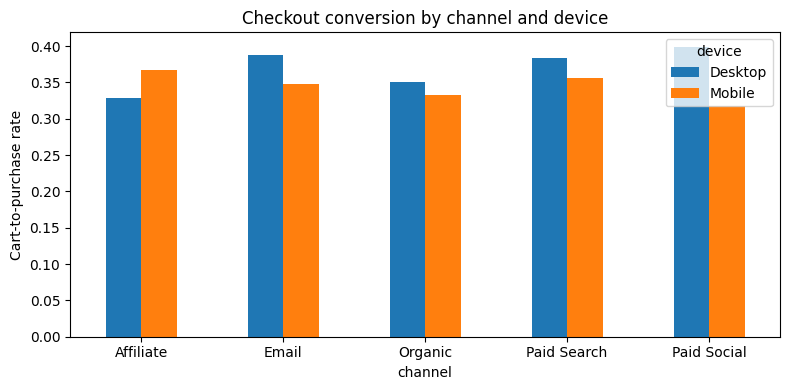

In [ ]:
# Cell 4: chart of conversion by device and channel
import matplotlib.pyplot as plt
ch = client.query("""
SELECT channel, device, SAFE_DIVIDE(COUNTIF(purchased=1), COUNT(*)) AS conv
FROM `ecommerce.websession` WHERE added_to_cart = 1
GROUP BY 1, 2
""").to_dataframe()
ch.pivot(index='channel', columns='device', values='conv').plot(kind='bar', figsize=(8,4))
plt.ylabel('Cart-to-purchase rate'); plt.title('Checkout conversion by channel and device')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

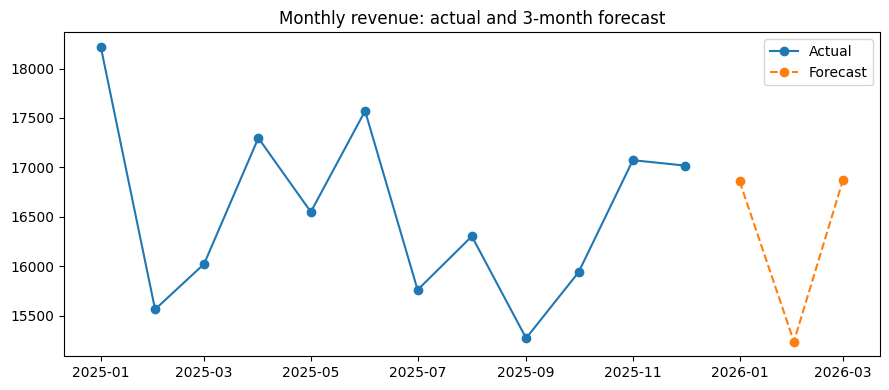

day
2026-01-01 00:00:00+00:00    16858.0
2026-02-01 00:00:00+00:00    15238.0
2026-03-01 00:00:00+00:00    16870.0
Freq: MS, Name: forecast_value, dtype: float64


In [ ]:
# Cell 5: forecast chart (works with the BigQuery ML model)
hist = client.query("SELECT day, revenue FROM `ecommerce.daily_revenue` ORDER BY day").to_dataframe()
fc = client.query("""
SELECT forecast_timestamp AS day, forecast_value,
       prediction_interval_lower_bound AS lo, prediction_interval_upper_bound AS hi
FROM ML.FORECAST(MODEL `ecommerce.revenue_forecast`, STRUCT(90 AS horizon, 0.9 AS confidence_level))
""").to_dataframe()

m_hist = hist.set_index('day')['revenue'].astype(float).resample('MS').sum()
m_fc = fc.set_index('day')['forecast_value'].resample('MS').sum()
plt.figure(figsize=(9,4))
plt.plot(m_hist.index, m_hist.values, marker='o', label='Actual')
plt.plot(m_fc.index, m_fc.values, marker='o', linestyle='--', label='Forecast')
plt.title('Monthly revenue: actual and 3-month forecast'); plt.legend(); plt.tight_layout(); plt.show()
print(m_fc.round(0))

In [ ]:
import pandas as pd
from google.colab import files
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)

queries = {
"4a Row counts & dates": """
SELECT 'websession' AS tbl, COUNT(*) AS n, MIN(sessiondate) AS first_dt, MAX(sessiondate) AS last_dt
FROM `ecommerce.websession`
UNION ALL
SELECT 'orders', COUNT(*), MIN(sessiondate), MAX(sessiondate) FROM `ecommerce.orders`""",

"4c Grain": """
SELECT
  (SELECT COUNT(*) - COUNT(DISTINCT sessionid) FROM `ecommerce.websession`) AS duplicate_sessions,
  (SELECT COUNT(*) / COUNT(DISTINCT sessionid) FROM `ecommerce.orders`)     AS rows_per_order""",

"4d Consistency": """
SELECT
  COUNTIF(w.purchased = 1 AND o.sessionid IS NULL)     AS purchased_but_no_order,
  COUNTIF(w.purchased = 0 AND o.sessionid IS NOT NULL) AS order_but_not_purchased,
  COUNTIF(w.purchased = 1 AND w.added_to_cart = 0)     AS purchased_without_cart
FROM `ecommerce.websession` w
LEFT JOIN (SELECT DISTINCT sessionid FROM `ecommerce.orders`) o USING (sessionid)""",

"6a Funnel by device": """
SELECT device, COUNT(*) AS sessions, SUM(added_to_cart) AS carts, SUM(purchased) AS purchases,
  ROUND(SAFE_DIVIDE(COUNTIF(added_to_cart=1 AND purchased=1), SUM(added_to_cart)), 4) AS cart_to_purchase,
  ROUND(SAFE_DIVIDE(SUM(purchased), COUNT(*)), 4) AS session_conversion
FROM `ecommerce.websession` GROUP BY device""",

"6b Conversion by channel & device": """
SELECT channel, device, COUNT(*) AS sessions,
  ROUND(SAFE_DIVIDE(SUM(purchased), COUNT(*)), 4) AS conversion
FROM `ecommerce.websession` GROUP BY 1, 2 ORDER BY 1, 2""",

"6c Monthly revenue": "SELECT * FROM `ecommerce.monthly_revenue` ORDER BY month",

"6d Category revenue": """
SELECT category, ROUND(SUM(order_value), 2) AS revenue, SUM(units) AS units
FROM `ecommerce.orders` GROUP BY category ORDER BY revenue DESC""",

"6e Discount effect": """
SELECT discount_applied, COUNT(*) AS orders, ROUND(AVG(order_value), 2) AS aov
FROM `ecommerce.order_summary` GROUP BY discount_applied""",

"6f AOV by device": """
SELECT device, COUNT(*) AS orders, ROUND(AVG(order_value), 2) AS aov
FROM `ecommerce.order_summary` GROUP BY device""",

"7b A/B test result": "SELECT * FROM `ecommerce.ab_result`",

"7c Carted conversion by channel & device": "SELECT * FROM `ecommerce.ab_by_channel` ORDER BY channel, device",

"7d Revenue per carted session": """
WITH s AS (
  SELECT LOWER(w.device) AS device, IFNULL(o.order_value, 0) AS rev
  FROM `ecommerce.websession` w
  LEFT JOIN `ecommerce.order_summary` o USING (sessionid)
  WHERE w.added_to_cart = 1 AND LOWER(w.device) IN ('mobile','desktop'))
SELECT device, COUNT(*) AS n, ROUND(AVG(rev), 2) AS mean_rev, ROUND(STDDEV_SAMP(rev), 2) AS sd_rev
FROM s GROUP BY device""",

"8a Backtest (Nov-Dec)": """
WITH f AS (
  SELECT DATE_TRUNC(DATE(forecast_timestamp), MONTH) AS month, SUM(forecast_value) AS forecast
  FROM ML.FORECAST(MODEL `ecommerce.revenue_backtest`, STRUCT(61 AS horizon)) GROUP BY month),
a AS (
  SELECT DATE_TRUNC(DATE(day), MONTH) AS month, SUM(revenue) AS actual
  FROM `ecommerce.daily_revenue` WHERE day >= TIMESTAMP('2025-11-01') GROUP BY month)
SELECT month, ROUND(actual, 0) AS actual, ROUND(forecast, 0) AS forecast
FROM a JOIN f USING (month) ORDER BY month""",

"8b Actual vs forecast": "SELECT * FROM `ecommerce.revenue_actual_vs_forecast` ORDER BY month, series",
}

lines = []
for name, sql in queries.items():
    lines.append(f"\n===== {name} =====")
    try:
        lines.append(client.query(sql).to_dataframe().to_string(index=False))
    except Exception as e:
        lines.append(f"ERROR: {str(e).splitlines()[0][:200]}")

report = "\n".join(lines)
print(report)
with open("project_results.txt", "w") as f:
    f.write(report)
files.download("project_results.txt")


===== 4a Row counts & dates =====
ERROR: name 'client' is not defined

===== 4c Grain =====
ERROR: name 'client' is not defined

===== 4d Consistency =====
ERROR: name 'client' is not defined

===== 6a Funnel by device =====
ERROR: name 'client' is not defined

===== 6b Conversion by channel & device =====
ERROR: name 'client' is not defined

===== 6c Monthly revenue =====
ERROR: name 'client' is not defined

===== 6d Category revenue =====
ERROR: name 'client' is not defined

===== 6e Discount effect =====
ERROR: name 'client' is not defined

===== 6f AOV by device =====
ERROR: name 'client' is not defined

===== 7b A/B test result =====
ERROR: name 'client' is not defined

===== 7c Carted conversion by channel & device =====
ERROR: name 'client' is not defined

===== 7d Revenue per carted session =====
ERROR: name 'client' is not defined

===== 8a Backtest (Nov-Dec) =====
ERROR: name 'client' is not defined

===== 8b Actual vs forecast =====
ERROR: name 'client' is not defined


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>